# Comparing ML Classifiers

Lab Assignment 6 - training a few different classification algorithms on the Breast Cancer Wisconsin dataset and comparing them on accuracy, precision and recall.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Data loading and exploration

The dataset comes bundled with sklearn. 569 samples, 30 numeric features computed from images of breast mass cell nuclei. Target is 0 = malignant, 1 = benign.

In [2]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape

(569, 31)

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [5]:
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

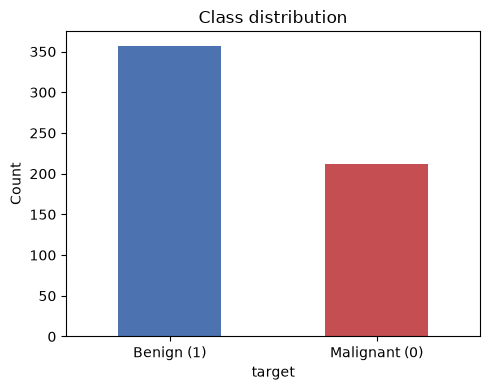

In [6]:
plt.figure(figsize=(5, 4))
df['target'].value_counts().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.xticks([0, 1], ['Benign (1)', 'Malignant (0)'], rotation=0)
plt.ylabel('Count')
plt.title('Class distribution')
plt.tight_layout()
plt.show()

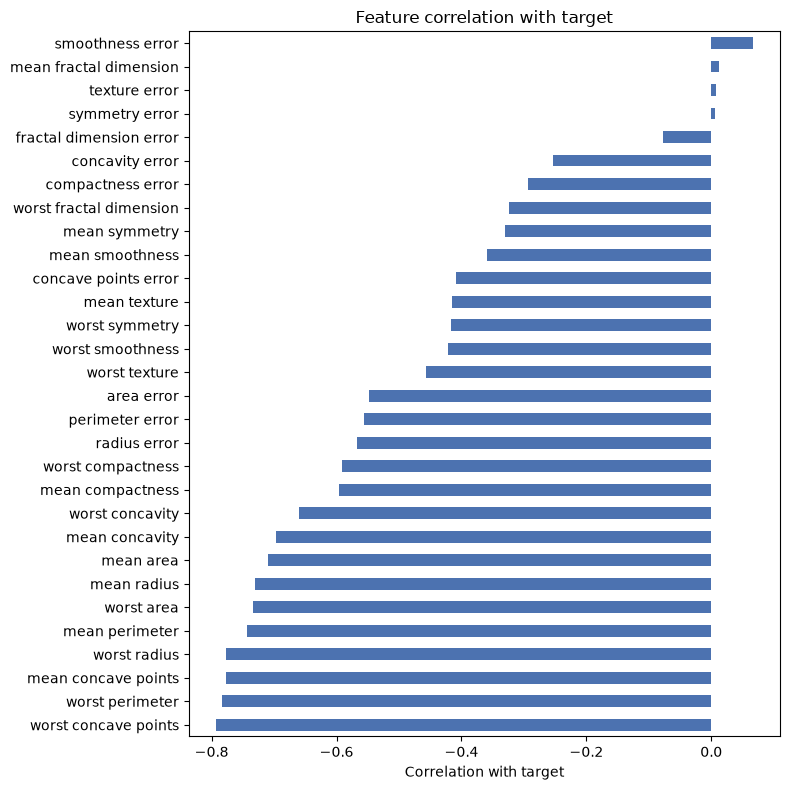

In [7]:
corr = df.corr()['target'].drop('target').sort_values()
plt.figure(figsize=(8, 8))
corr.plot(kind='barh', color='#4c72b0')
plt.xlabel('Correlation with target')
plt.title('Feature correlation with target')
plt.tight_layout()
plt.show()

## 2. Data preprocessing

No missing values or duplicates, so the only real preprocessing needed is scaling. The features are on very different ranges (area is in the hundreds/thousands while smoothness is below 0.2), which matters for KNN, SVM and Logistic Regression.

In [8]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [9]:
df[['mean area', 'mean smoothness', 'worst area', 'mean fractal dimension']].describe().loc[['min', 'max', 'mean']]

,mean area,mean smoothness,worst area,mean fractal dimension
min,143.500000,0.05263,185.200000,0.049960
max,2501.000000,0.16340,4254.000000,0.097440
mean,654.889104,0.09636,880.583128,0.062798


## 3. Data splitting

80/20 split, stratified so both sets keep the same benign/malignant ratio. The scaler is fit only on the training set.

In [10]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 4. Model training

Six classifiers from different families - linear, distance based, kernel based, tree based, ensemble and probabilistic.

In [11]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Naive Bayes': GaussianNB()
}

predictions = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)

## 5. Model evaluation

In [12]:
results = []
for name, y_pred in predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results = pd.DataFrame(results).set_index('Model')
results.round(4)

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861
KNN,0.9561,0.9589,0.9722,0.9655
SVM,0.9825,0.9861,0.9861,0.9861
Decision Tree,0.9123,0.9559,0.9028,0.9286
Random Forest,0.9561,0.9589,0.9722,0.9655
Naive Bayes,0.9298,0.9444,0.9444,0.9444


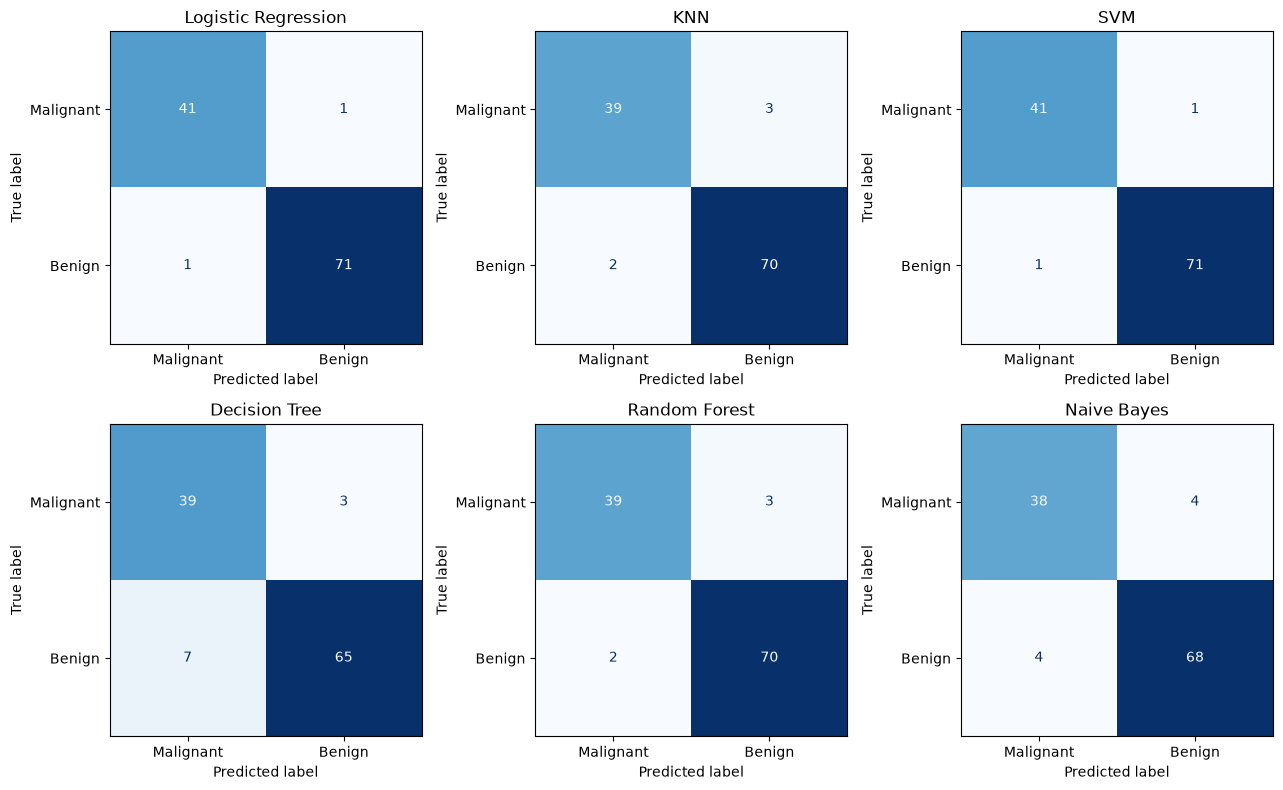

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Malignant', 'Benign']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Visualization and comparison

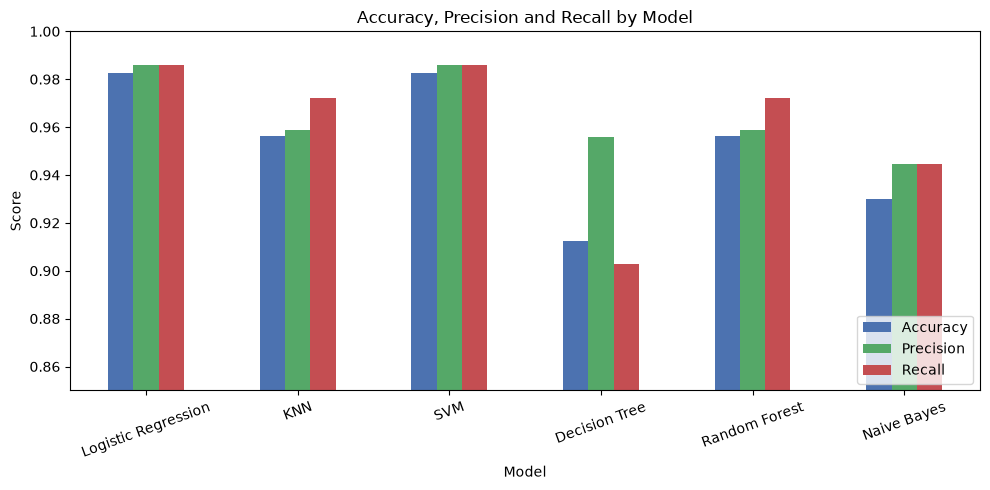

In [14]:
results[['Accuracy', 'Precision', 'Recall']].plot(kind='bar', figsize=(10, 5), color=['#4c72b0', '#55a868', '#c44e52'])
plt.ylabel('Score')
plt.title('Accuracy, Precision and Recall by Model')
plt.ylim(0.85, 1.0)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [15]:
results.sort_values('Accuracy', ascending=False).round(4)

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861
SVM,0.9825,0.9861,0.9861,0.9861
KNN,0.9561,0.9589,0.9722,0.9655
Random Forest,0.9561,0.9589,0.9722,0.9655
Naive Bayes,0.9298,0.9444,0.9444,0.9444
Decision Tree,0.9123,0.9559,0.9028,0.9286


## 7. 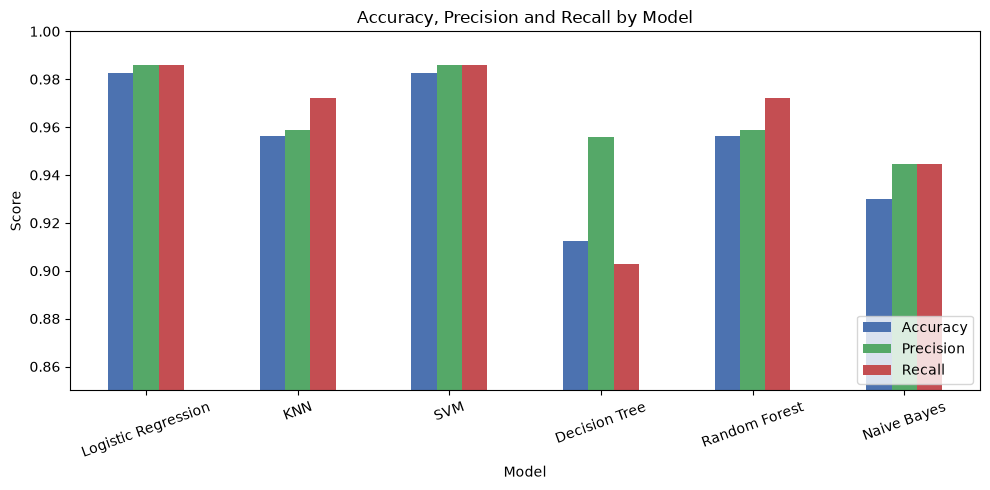

Grid search over the SVM since it was one of the top two models.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

grid = GridSearchCV(SVC(random_state=42), param_grid, cv=cv, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best params: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV accuracy: 0.9758


In [17]:
y_pred_tuned = grid.predict(X_test_scaled)
print("Accuracy :", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tuned), 4))

Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861


## Bonus 1 - Effect of feature scaling

Same models trained on the raw unscaled features to see how much scaling actually helps.

In [18]:
raw_acc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    raw_acc[name] = accuracy_score(y_test, model.predict(X_test))

scaling = pd.DataFrame({'Without scaling': pd.Series(raw_acc), 'With scaling': results['Accuracy']})
scaling.round(4)

,Without scaling,With scaling
Logistic Regression,0.9649,0.9825
KNN,0.9123,0.9561
SVM,0.9298,0.9825
Decision Tree,0.9123,0.9123
Random Forest,0.9561,0.9561
Naive Bayes,0.9386,0.9298


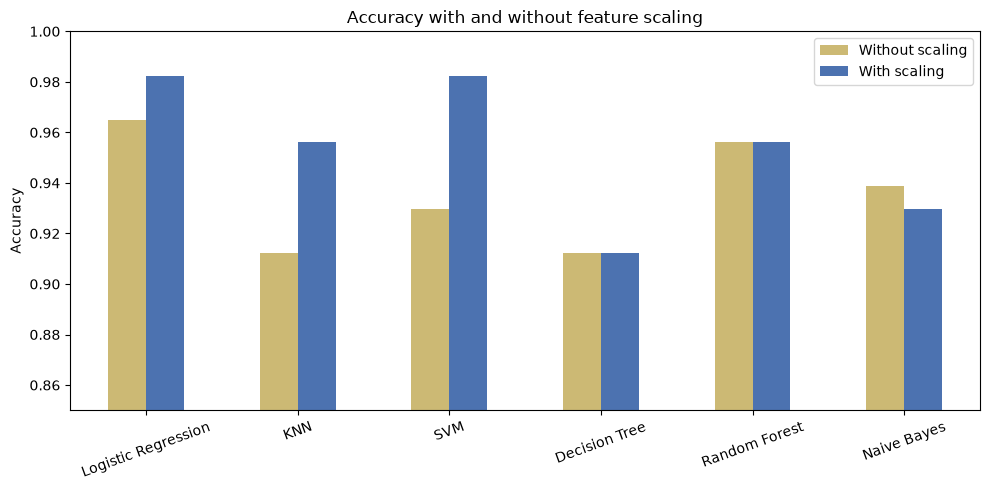

In [19]:
scaling.plot(kind='bar', figsize=(10, 5), color=['#ccb974', '#4c72b0'])
plt.ylabel('Accuracy')
plt.title('Accuracy with and without feature scaling')
plt.ylim(0.85, 1.0)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Bonus 2 - Cross-validation

5-fold stratified CV on the full dataset. The scaler is inside a pipeline so it gets refit on each fold and nothing leaks from the validation fold.

In [20]:
cv_results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
    cv_results[name] = scores

cv_summary = pd.DataFrame({
    'CV Mean': {k: v.mean() for k, v in cv_results.items()},
    'CV Std': {k: v.std() for k, v in cv_results.items()},
    'Test Accuracy': results['Accuracy']
})
cv_summary.round(4)

,CV Mean,CV Std,Test Accuracy
Logistic Regression,0.9737,0.0166,0.9825
KNN,0.9631,0.0179,0.9561
SVM,0.9772,0.0163,0.9825
Decision Tree,0.9104,0.0279,0.9123
Random Forest,0.9543,0.0102,0.9561
Naive Bayes,0.9297,0.0199,0.9298


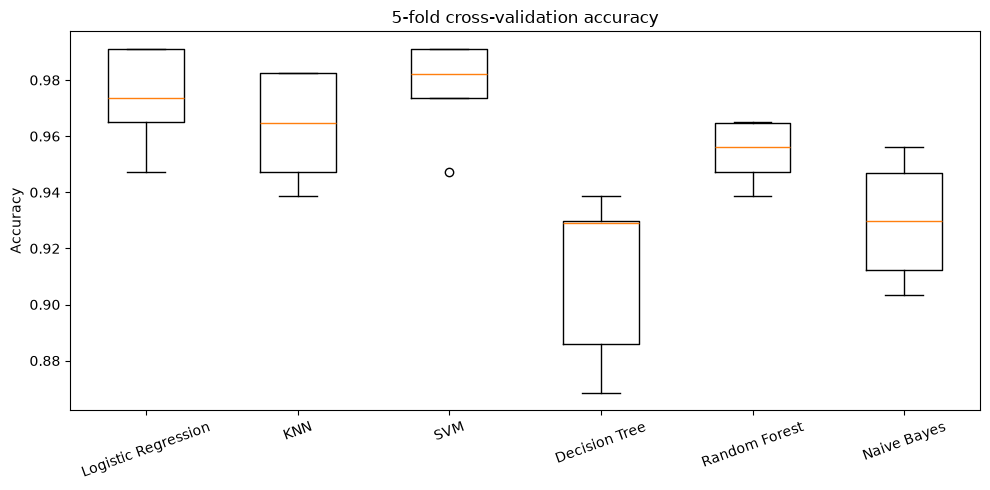

In [21]:
plt.figure(figsize=(10, 5))
plt.boxplot(list(cv_results.values()), tick_labels=list(cv_results.keys()))
plt.ylabel('Accuracy')
plt.title('5-fold cross-validation accuracy')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Observations

Logistic Regression and SVM tied for the best test results with 98.2% accuracy and 98.6% for both precision and recall, only misclassifying 2 of the 114 test samples. KNN and Random Forest were close behind at 95.6%, Naive Bayes got 93.0% and the single Decision Tree was the weakest at 91.2%, with the lowest recall (90.3%) of any model. That makes sense since a single tree overfits easily, and the dataset is close to linearly separable, which favors the linear and kernel models.

Precision and recall here are for the benign class (label 1). In a real diagnosis setting the more important number is how many malignant cases get missed, which shows up in the confusion matrices as malignant samples predicted as benign. LR and SVM only had one of those each.

Grid search picked a linear kernel with C=0.1 for the SVM (CV accuracy 97.6%), and it scored the same on the test set as the default RBF SVM, so tuning didn't add much here.

Scaling made a big difference for the distance and margin based models: SVM went from 93.0% to 98.2% and KNN from 91.2% to 95.6%. Logistic Regression also improved (96.5% to 98.2%). The Decision Tree and Random Forest didn't change at all since tree splits don't care about feature scale.

Cross-validation backs up the test results. SVM (97.7%) and Logistic Regression (97.4%) had the highest mean accuracy, and the Decision Tree had both the lowest mean (91.0%) and the largest spread across folds, so it is the least stable of the six.

## Conclusion

In this experiment six different ML classifiers were applied to the Breast Cancer Wisconsin dataset and compared on accuracy, precision and recall. Logistic Regression and SVM performed the best with 98.2% accuracy and 98.6% precision and recall, while the Decision Tree performed the worst at 91.2% accuracy. Since the dataset is close to linearly separable, simple linear and kernel based models did better than the tree based ones, and a single decision tree overfit the most.

Feature scaling turned out to be an important preprocessing step for models that depend on distances or margins like SVM, KNN and Logistic Regression, while tree based models were not affected by it. Hyperparameter tuning of the SVM did not improve the test results much, which shows the default settings were already a good fit for this data. Cross-validation gave results consistent with the test set, which confirms the models are robust and the comparison is not just because of one lucky split.

Overall, accuracy alone is not enough to judge a classifier. Precision and recall, along with the confusion matrix, give a better picture, especially in a medical problem like this where missing a malignant case is much more costly than a false alarm. Based on all the metrics, Logistic Regression or SVM would be the best choice for this classification task.